# 결정 트리 (Decision Tree)

머신러닝 알고리즘 중에서 **결정 트리(Decision Tree)** 는 가장 직관적이고 이해하기 쉬운 모델 중 하나이다. 마치 스무고개 게임처럼 일련의 질문을 통해 답에 도달하는 방식으로 작동하며, 그 과정을 시각화할 수 있어 "화이트박스(white-box)" 모델로 분류된다.

### 결정 트리의 기본 아이디어

우리가 일상에서 의사결정을 내리는 방식을 생각해보자. 예를 들어 "오늘 우산을 가져갈까?"를 결정할 때:

```
비가 올 확률이 높은가?
├─ 예 → 우산을 가져간다
└─ 아니오 → 외출 시간이 긴가?
    ├─ 예 → 우산을 가져간다 (혹시 몰라서)
    └─ 아니오 → 우산을 두고 간다
```

결정 트리는 바로 이러한 **분기 구조**를 데이터로부터 자동으로 학습한다. 각 분기점(노드)에서 데이터를 가장 잘 나누는 질문을 찾아내고, 이를 반복하여 최종 예측(잎)에 도달한다.

### 선형 모델과의 차이

지금까지 살펴본 선형 회귀나 로지스틱 회귀는 **선형 모델(linear model)** 로, 특성들의 가중치 합으로 예측을 수행한다:

$$
\hat{y} = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b
$$

이러한 선형 모델은 다음과 같은 특징이 있다:

- **장점**: 계산이 빠르고, 해석이 비교적 간단함
- **한계**: 선형 관계만 포착 가능, 특성 간 복잡한 상호작용 포착 어려움

반면, **결정 트리는 비선형 모델(non-linear model)**로, 데이터를 여러 영역으로 나누어 각 영역마다 다른 예측을 수행한다. 이를 통해:

- 특성 간의 **복잡한 상호작용** 자동 포착
- **비선형 관계** 모델링 가능
- 특성 스케일링 불필요
- 수치형/범주형 데이터 모두 처리 가능


### 결정 트리의 장점

1. **직관적 해석**: 의사결정 과정을 시각화하고 설명 가능
2. **전처리 최소화**: 특성 스케일링 불필요, 결측치 처리 용이
3. **비선형 관계 포착**: 복잡한 경계 결정 가능
4. **다용도**: 분류와 회귀 모두 가능
5. **특성 중요도**: 어떤 특성이 예측에 중요한지 파악 가능

### 결정 트리의 단점

1. **과적합 경향**: 제약 없이 학습하면 훈련 데이터를 완벽히 암기
2. **불안정성**: 데이터 작은 변화에 민감
3. **편향된 트리**: 특성 값이 많은 범주형 변수에 편향

### 확률적 경사 하강법과의 차이

앞서 서술한 로지스틱 회귀는 **확률적 경사 하강법**을 사용하여 손실 함수를 최소화하는 방식으로 학습했다:

```
반복적 최적화:
1. 손실 함수 계산
2. 기울기 계산
3. 파라미터 업데이트
4. 수렴할 때까지 반복
```

반면, 결정 트리는 **탐욕적 알고리즘(greedy algorithm)**을 사용한다:

```
재귀적 분할:
1. 현재 노드에서 최선의 분할 찾기
2. 데이터를 두 그룹으로 나누기
3. 각 그룹에 대해 1-2 반복
4. 정지 조건 만족 시 종료
```

이는 **전역 최적화가 아닌 지역 최적화**이지만, 계산이 효율적이고 해석이 용이하다는 장점이 있다.

이제 결정 트리가 어떻게 데이터를 학습하고, 예측을 수행하며, 그 과정을 해석할 수 있는지 실습을 통해 알아보자.

`pands`를 이용해 데이터를 가져온다.
> 가져오는 데이터는 kaggle의 Red Wine Quality 데이터셋의 일부이다.
> [데이터셋 원본 링크](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)

In [9]:
import pandas as pd
wine = pd.read_csv('https://raw.githubusercontent.com/rickiepark/hg-mldl/master/wine.csv')

읽어들인 내용을 `head()`로 일부만 출력한다.

In [10]:
wine.head()

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0
3,9.8,1.9,3.16,0.0
4,9.4,1.9,3.51,0.0


3개의 열(각각 `alchol`, `sugar`, `pH`)는 알코올 도수, 당도, pH값을 나타냅니다.\
네 번째 열(`class`)는 타깃값으로, `0`이면 레드 와인, `1`이면 화이트 와인이라고 한다.

즉, 레드 와인과 화이트 와인을 분류하는 이진 분류 문제이고,\
레드 와인이 음성 클래스, 화이트 와인이 양성 클래스이다.

`pandas`는 데이터프레임의 정보를 확인할 수 있는 함수들이 있다.

`info()` 메서드는 데이터프레임의 각 열의 데이터 타입과 누락된 데이터가 있는지 확인하는데 사용한다.

In [11]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


출력은 6497개의 샘플이 있고, 4개의 열은 모두 실수이다.\
`Non-Null`(`Null`이 아님)이 모두 6497이므로 누락된 값은 없다.\
따라서 이 데이터셋에는 결측값이 없다.

다음 메서드는 `describe()`이다. 이 메서드는 열에 대한 간략한 통계값을 출력한다.\
해당 열의 샘플 개수, 평균, 표준편차, 최솟값, 최댓값, 1사분위수, 중간값(2사분위수), 3사분위수 등을 제공한다.

In [12]:
wine.describe()

,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


> 사분위수는 데이터를 순서대로 4등분 한 것이다.\
> 예를 들어 2사분위수(중간값)은 데이터를 일렬로 늘어놓았을 때 정중앙의 값이다.\
> 데이터의 값이 짝수로 완전히 4등분이 불가능하다면 중앙의 2개의 샘플의 값의 평균을 사용한다.

훈련을 위한 3가지 값의 스케일이 모두 달라 보이니, `StandardScaler`로 전처리 후 데이터를 이용한다.

데이터프레임에서의 특성(`alcohol`, `sugar`, `pH`)과 타깃(`class`)를 추출한다.


In [13]:
data = wine[['alcohol', 'sugar', 'pH']]
target = wine['class']

`train_test_split`을 이용해 훈련 세트와 테스트 세트로 나눈다.

In [14]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(data, target, random_state=42, test_size=0.2)

전체 데이터의 양이 충분히 많으므로 테스트 세트의 크기를 전체 데이터세트의 $20\%$ 정도로 조절했다.
> 기본값은 `0.25`, $25\%$ 정도를 테스트 세트로 지정한다.

In [15]:
print(train_input.shape, test_input.shape)

(5197, 3) (1300, 3)


훈련 세트는 5197개이고 테스트 세트는 1300개이다.\
이제 표준화 전처리를 진행한다.

In [16]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
train_input_scaled = ss.fit_transform(train_input)
test_input_scaled = ss.transform(test_input)

데이터가 준비되었다.\
이제 로지스틱 회귀 모델로 먼저 훈련하여 결과를 확인해보자.

In [17]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(train_input_scaled, train_target)
print(lr.score(train_input_scaled, train_target))
print(lr.score(test_input_scaled, test_target))

0.7808350971714451
0.7776923076923077


점수가 테스트 세트와 훈련 세트 모두 낮다.\
따라서, 과소적합된 모델이다.

In [18]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()
kn.fit(train_input_scaled, train_target)
print(kn.score(train_input_scaled, train_target))
print(kn.score(test_input_scaled, test_target))

0.90186646142005
0.8338461538461538


knn에 대해서는 훈련 세트의 점수는 높지만 테스트 세트의 점수는 낮다.
따라서, 과대적합된 모델이다.

위의 두 문제는 모델들의 규제값이나 알고리즘을 약간 변경하여 수정이 가능할 수 있다.\
다만, 이에는 한계가 있으므로 다른 모델을 이용해본다.

## Explainable Model, Black Box Model
각각 설명하기 쉬운 모델, 설명하기 어려운 모델로 부를 수 있다.\
위에서 사용한 로지스틱 회귀 모델을 설명하려면, 모델이 학습한 값들을 가져와 설명하여야 한다.

In [19]:
print(lr.coef_, lr.intercept_)

[[ 0.51268071  1.67335441 -0.68775646]] [1.81773456]


위의 절편값들을 토대로 설명하는 글을 작성한다면:
```text
로지스틱 회귀 모델 해석
학습된 모델의 파라미터
이 로지스틱 회귀 모델은 3개의 특성을 사용하여 와인을 레드 와인(0)과 화이트 와인(1)으로 분류합니다. 학습이 완료된 모델의 파라미터는 다음과 같습니다.
계수(coefficients):
첫 번째 특성(alcohol): 0.513
두 번째 특성(sugar): 1.673
세 번째 특성(pH): -0.688
절편(intercept): 1.818
모델의 예측 과정
이 모델은 다음과 같은 수식으로 예측을 수행합니다.
1단계: 로짓(logit) 계산
z = 0.513 × alcohol + 1.673 × sugar - 0.688 × pH + 1.818
2단계: 확률로 변환 (시그모이드 함수)
확률 = 1 / (1 + e^(-z))
3단계: 분류 결정
확률이 0.5 이상이면 화이트 와인(1), 미만이면 레드 와인(0)으로 분류합니다.
구체적인 예시
예를 들어, 다음과 같은 특성을 가진 와인이 있다고 가정해봅시다.
alcohol = 12.0%
sugar = 3.0 g/L
pH = 3.2
계산 과정:
z = 0.513 × 12.0 + 1.673 × 3.0 - 0.688 × 3.2 + 1.818
z = 6.156 + 5.019 - 2.202 + 1.818
z = 10.791
확률 = 1 / (1 + e^(-10.791)) ≈ 0.9999
이 와인은 약 99.99%의 확률로 화이트 와인으로 예측됩니다.
각 특성의 영향력 해석
sugar (1.673): 가장 큰 양의 계수
당도가 1 g/L 증가하면 화이트 와인일 확률이 크게 증가합니다.
화이트 와인이 일반적으로 당도가 높다는 것을 모델이 학습했습니다.
alcohol (0.513): 중간 크기의 양의 계수
알코올 도수가 1% 증가하면 화이트 와인일 확률이 증가합니다.
당도보다는 영향이 적지만 여전히 중요한 특성입니다.
pH (-0.688): 음의 계수
pH가 1 증가하면 화이트 와인일 확률이 감소합니다.
즉, pH가 낮을수록(산성이 강할수록) 화이트 와인으로 분류될 가능성이 높습니다.
intercept (1.818): 양의 절편
모든 특성이 0일 때의 기본 경향성입니다.
양수이므로 기본적으로 화이트 와인 쪽으로 약간 편향되어 있습니다.
```
위와 같이 길게 설명한다. 모델을 쉽게 이해하기는 쉽지 않을 것이다.\
또한, 특성 공학을 이용해 다항 특성을 사용한다면 이는 더 어려워질 것이다.

이렇게, 대부분의 머신러닝 모델들은 **학습의 결과를 설명하기 어렵다.**
> 사실, 로지스틱 회귀는 모델 중에서는 설명하기 쉬운 편에 속한다.\
> 다만 이전에 서술한 모델을 기준으로 쉽게 쉬운 모델과 어려운 모델의 차이를 설명하기 위해 참조했다.

## 결정 트리(Decision Tree)
**결정 트리(Decision Tree)** 모델은 머신러닝 모델이 왜 이러한 결과를 도출했는지 이유를 확인하기 쉽다.\
결정 트리를 비유하자면 질문을 20번 하며 답을 찾아가는 스무고개와 비슷한 성질을 띄고 있다.

데이터를 잘 나눌 수 있는 질문을 찾는다면 질문을 계속 추가하여 분류의 정확도를 높일 수 있다.\
`sklearn`에서는 `DecisionTreeClassifier` 클래스를 사용해 결정 트리 모델을 훈련할 수 있다.

결정 트리를 이용한 분류의 한 예로 스팸 메일 판별을 들 수 있다.\
메일 제목에 광고성 키워드가 포함되어 있는지, 발신자가 신뢰할 수 있는 주소인지, 본문에 의심스러운 링크가 있는지 등의 조건을 차례대로 확인하여 최종적으로 해당 메일을 스팸 또는 정상 메일로 분류한다.\
또 다른 예로는 고객의 대출 승인 여부 분류가 있다. 소득 수준, 신용 점수, 연체 이력 등의 조건을 기준으로 대출 승인 또는 거절로 구분한다.

`sklearn`의 `DecisionTreeClassifier`는 노드에서 최적의 분할을 찾기 전에 특성의 순서를 섞은 다음 분할에 사용할 일부 특성을 선택한다.\
모든 특성을 사용하는 경우에도 성능이 동일한 두 개의 분기점이 있다면 랜덤하게 한 가지를 선택한다.\
이에 따라 경우마다 분기되는 지점이 달라질 수 있다.

> 회귀 모델도 존재한다. 회귀 모델은 `DecisionTreeRegressor`이다. 자세한 내용은 후술한다.

결정 트리 클래스는 `sklearn.tree` 내에 위치한다.

In [20]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(train_input_scaled, train_target)
print(dt.score(train_input_scaled, train_target))
print(dt.score(test_input_scaled, test_target))

0.996921300750433
0.8592307692307692


훈련 세트에 대한 점수가 매우 높다.
> 상대적으로 과대적합이다.

만들어진 모델을 그림으로도 나타낼 수 있다.\
`plot_tree()` 메서드를 이용한다.
> 또한, `matplotlib`를 불러와야 한다.
> 시간이 상당히 걸릴 수 있다.

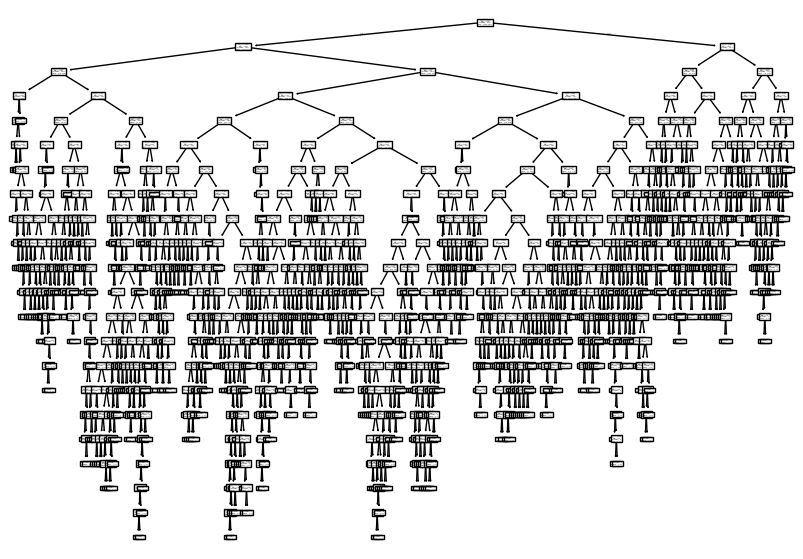

In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(10, 7)) # 튜플, 10:7의 플롯 이미지
plot_tree(dt)
plt.show()

매우 많은 양의 노드가 존재한다.\
가장 상위의 노드를 **루트 노드(root node)** 라 부르고, 가장 아래의 노드를 **리프 노드(leaf node)** 라 부른다.\
하나의 노드는 분류 조건을 다루며, 하나의 노드는 2개의 브랜치(branch)를 가질 수 있다. 각 브랜치는 참과 거짓(True, False)를 담당한다.

`plot_tree()`에서 트리의 깊이를 제한하여 루트 노드만 보이게 하면 각 노드를 정확히 볼 수 있다.
매개변수를 설명하면:
- `max_depth` 기본 매개변수를 1로 지정하면 루트 노드와 다음 2개의 노드를 볼 수 있다.
- `filled` 불 값을 받고, 각 노드에 색이 칠해져있는 여부를 결정한다.
- `feature_names` 특성의 이름을 전달할 수 있다.

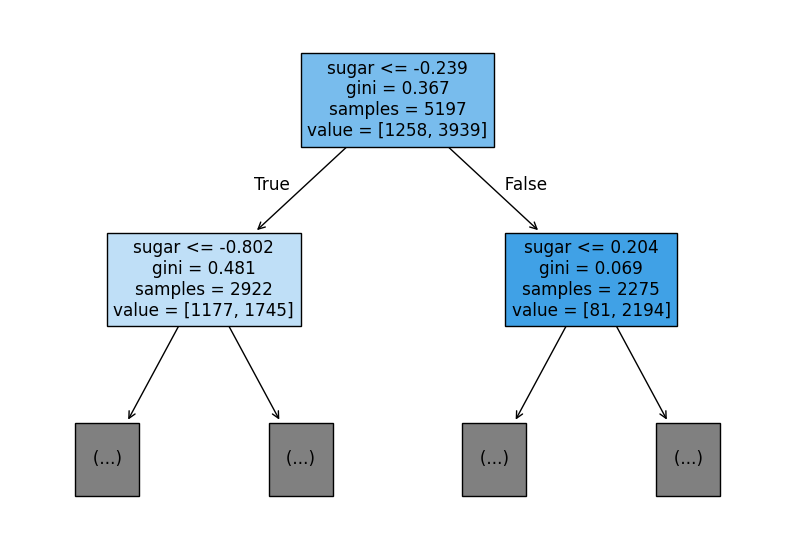

In [22]:
plt.figure(figsize=(10, 7)) # 10:7 비율
plot_tree(dt, max_depth=1, feature_names=['alcohol', 'sugar', 'pH'], filled=True)
plt.show()

각 노드들을 해석해보자.\
루트 노드는 `sugar`을 기준으로 본다. `sugar`이 `-0.239` 이하라면 True, 즉, 왼쪽 브랜치로, 이하가 아니라면 False, 즉, 오른쪽 브랜치로 이동한다.\
루트 노드의 총 샘플 수는 `5197`이다. 훈련 샘플의 개수와 같다.\
이 중 음성 클래스(레드 와인)은 `1258`개이고, 양성 클래스(화이트 와인)은 `3939`개이다. 이 값은 `value`에 배열로 나타나 있다.

왼쪽 자식 노드는 `sugar <= -0.802`를 기준으로 다시 한 번 분기한다.\
이 노드에 도달한 샘플 수는 `2922`개이다. 이는 루트에서 `sugar <= -0.239` 조건을 만족한 데이터만 모인 것이다.\
이 중 음성 클래스(레드 와인)는 `1177`개, 양성 클래스(화이트 와인)는 `1745`개이다.\
`gini = 0.481`로, 루트 노드보다 불순도가 조금 증가한 상태이다.

오른쪽 자식 노드는 `sugar <= 0.204`를 기준으로 분기한다.\
이 노드에 도달한 샘플 수는 `2275`개이다. 이는 루트에서 `sugar > -0.239`인 데이터들이다.\
이 중 음성 클래스(레드 와인)는 `81`개, 양성 클래스(화이트 와인)는 `2194`개이다.\
`gini = 0.069`로 매우 낮아, 거의 대부분이 화이트 와인으로 구성된 노드임을 알 수 있다.

시각화된 정보를 보면, 오른쪽 노드의 색이 다른 노드보다 진하다.\
오른쪽 자식 노드는 특정 클래스의 비율(화이트 와인의 비율)이 높음을 확인할 수 있다.\
따라서, 시각화된 트리의 색의 진하기는 특정 클래스의 비율이 높을 때 점점 진해지는 것을 확인할 수 있다.

회귀 모델인 `DecisionTreeRegressor`의 경우 리프 노드에 도달한 샘플의 타깃을 평균하여 예측값으로 이용한다.

노드 내의 `gini` 값은 **지니 불순도(gini impurity)** 를 의미한다.
> `DecisionTreeRegressor` 클래스의 `criterion`을 변경하여 다른 불순도를 사용할 수 있다.\
> `entropy`를 이용하여 엔트로피 불순도를 이용할 수 있다.

지니 불순도는 다음과 같이 계산한다.
$$
Gini = 1 − (p₁² + p₂² + … + pₖ²)
$$

시그마 표기법으로
$$
Gini = 1 - \sum_{i=1}^{K} p_i^2
$$
* $k$: 클래스 개수
* $p_i$: 해당 노드에서 클래스 i의 비율

값이 0이면 완전히 순수한 노드이고, 값이 클수록 여러 클래스가 섞여 있다.
결정 트리에서 노드의 분할 기준으로 사용된다.


현재는 2개의 클래스반 분류하는 이진 분류이므로, 다음과 같은 식을 사용한다.
$$
Gini = 1 -(음성 클래스 비율^2 + 양성 클래스 비율^2)
$$
와 같이 계산할 수 있다.

루트 노드는 총 `5197`개의 클래스가 존재한다.\
루트 노드의 지니 불순도는:
$$
Gini = 1 − ( (1258 / 5197)^2 + (3939 / 5197)^2 )
$$
`0.367`(소수점 넷째 자리에서 반올림)이다.

만약 100개의 샘플 중 두 개의 클래스의 비율이 정확히 $\frac{1}{2}$라면 지니 불순도는 `0.5`가 된다.
$$
Gini = 1-((50/100)^2 + (50/100)^2 )
$$

## 정보 이득
결정 트리는 부모 노드와 하위 노드인 자식 노드의 불순도 차이가 가능한 크도록 트리를 성장시킨다.\
불순도는 부모 노드보다 자식 노드가 더 낮아지는 방향으로 진행되어야 한다.\
이를 위해 부모 노드와 자식 노드의 불순도 차이를 계산하는데, 이것을 **정보 이득(information gain)** 라고 한다.

정보 이득은 다음과 같이 구할 수 있다:
$$
IG = H(부모) - \left( \frac{N_{왼쪽}}{N_{부모}} H(왼쪽불순도) + \frac{N_{오른쪽}}{N_{부모}} H(오른쪽불순도) \right)
$$

* $H(부모)$: 분할 전 부모 노드의 불순도
* $H(왼쪽)$, $H(오른쪽)$: 분할 후 자식 노드의 불순도
* $N_{부모}$: 부모 노드의 데이터 수
* $N_{왼쪽}$, $N_{오른쪽}$: 각 자식 노드의 샘플 수


## 엔트로피 불순도
엔트로피 불순도의 경우 지니 불순도와는 다르게 클래스 비율을 계산할 때 밑이 2인 로그인 이진로그를 이용한다.

엔트로피(Entropy) 불순도 공식은 다음과 같다.

$$
H = - ( p_1 \log_2 p_1 + p_2 \log_2 p_2 + \cdots + p_k \log_2 p_k )
$$

* $p_1, p_2, \dots, p_k$: 각 클래스의 비율

$$
p_1 = \frac{1258}{5197}, \quad
p_2 = \frac{3939}{5197}
$$

$$
H = - \left( \frac{1258}{5197}\log_2\frac{1258}{5197}

+ \frac{3939}{5197}\log_2\frac{3939}{5197} \right)
$$

≈ **0.798**

일반적으로 지니 불순도와 엔트로피 불순도의 값 차이는 크지 않다.

의사결정트리 알고리즘은 불순도를 이용해 정보 이득이 최대가 되도로 노드를 분할하는 값을 찾는다.\
노드의 불순도를 낮추어 순수하게 만들수록 정보 이득이 커진다.\
새 샘플을 예측할 때에는 노드의 질문에 따라 트리를 이동한다.\
마지막 리프 노드의 클래스 비율을 이용하여 에측을 만든다.

## 제한
결정 트리의 분기 횟수를 제한하여 결정 트리의 정확도가 개선되는 경우가 있다.

In [23]:
dt_limited = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_limited.fit(train_input_scaled, train_target)
print('훈련 세트 점수:', dt_limited.score(train_input_scaled, train_target))
print('테스트 세트 점수:', dt_limited.score(test_input_scaled, test_target))

훈련 세트 점수: 0.8454877814123533
테스트 세트 점수: 0.8415384615384616


`max_depth=3`으로 제한한 결과, 훈련 세트의 점수는 약간 낮아졌지만 테스트 세트의 점수는 개선되었다.\
이처럼 결정 트리의 깊이를 제한하면 **과대적합을 방지**하고 일반화 성능을 높일 수 있다.\
`max_depth` 외에도 다양한 매개변수를 통해 결정 트리의 복잡도를 조절할 수 있다.

| 매개변수 | 설명 |
|---|---|
| `max_depth` | 트리의 최대 깊이 |
| `min_samples_split` | 노드를 나누기 위한 최소 샘플 수 |
| `min_samples_leaf` | 리프 노드가 되기 위한 최소 샘플 수 |

d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


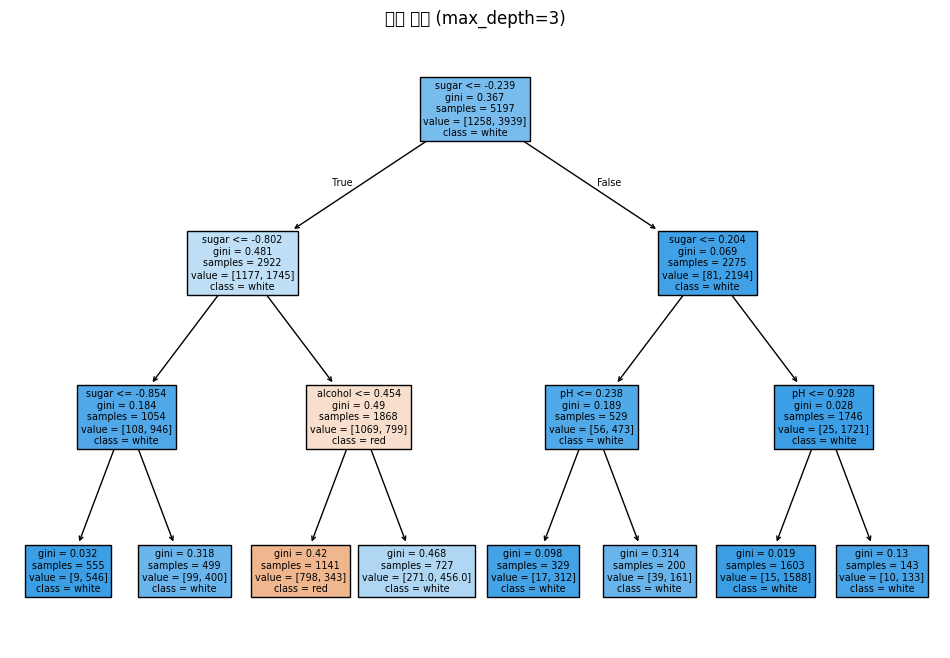

In [24]:
plt.figure(figsize=(12, 8))
plot_tree(
    dt_limited,
    max_depth=3,
    feature_names=['alcohol', 'sugar', 'pH'],
    class_names=['red', 'white'],
    filled=True
)
plt.title('결정 트리 (max_depth=3)')
plt.show()

## 특성 중요도 (Feature Importances)

결정 트리는 각 특성이 예측에 얼마나 중요하게 쓰였는지를 수치로 나타낼 수 있다.\
이를 **특성 중요도(Feature Importances)** 라고 한다.

훈련이 완료된 결정 트리 모델의 `feature_importances_` 속성으로 확인할 수 있으며,\
모든 값의 합은 항상 `1`이 된다.

값이 클수록 해당 특성이 분류에 큰 영향을 준다는 것을 의미한다.

특성 중요도: [0.12345626 0.86862934 0.0079144 ]


d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\MLDL\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


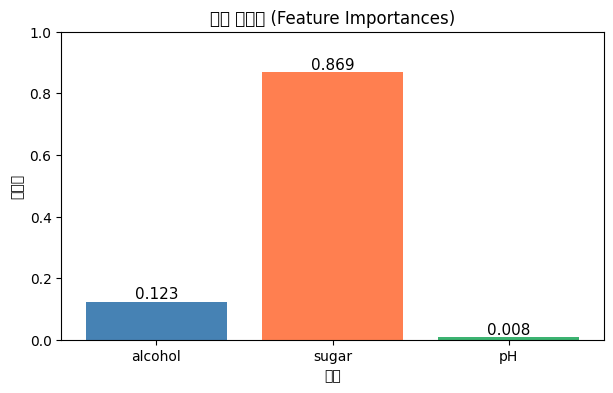

In [25]:
print('특성 중요도:', dt_limited.feature_importances_)

features = ['alcohol', 'sugar', 'pH']
importances = dt_limited.feature_importances_

plt.figure(figsize=(7, 4))
plt.bar(features, importances, color=['steelblue', 'coral', 'mediumseagreen'])
plt.title('특성 중요도 (Feature Importances)')
plt.xlabel('특성')
plt.ylabel('중요도')
plt.ylim(0, 1)
for i, v in enumerate(importances):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=11)
plt.show()

결과를 보면 `sugar`(당도)가 가장 높은 중요도를 가지고 있다.\
즉, 레드 와인과 화이트 와인을 분류하는 데 있어 **당도가 가장 핵심적인 특성**임을 알 수 있다.\
`alcohol`이 두 번째, `pH`가 세 번째로 중요하다.

이처럼 특성 중요도는 결정 트리가 어떤 특성에 주목하여 예측을 수행했는지 해석할 수 있도록 도와주는\
**설명 가능한 모델(Explainable Model)** 의 대표적인 장점이다.

## 전처리 불필요 확인

결정 트리는 특성의 스케일(크기)에 무관하게 동작한다.\
이는 각 노드에서 단순히 하나의 특성값과 임계값을 비교하기 때문이다.

따라서 `StandardScaler`로 스케일링하지 않은 원본 데이터로도 동일한 결과를 얻을 수 있는지 확인해보자.

In [26]:
dt_noscale = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_noscale.fit(train_input, train_target)  # 원본 데이터(스케일링 없음)
print('훈련 세트 점수 (스케일링 없음):', dt_noscale.score(train_input, train_target))
print('테스트 세트 점수 (스케일링 없음):', dt_noscale.score(test_input, test_target))

훈련 세트 점수 (스케일링 없음): 0.8454877814123533
테스트 세트 점수 (스케일링 없음): 0.8415384615384616


스케일링을 하지 않아도 점수가 동일하게 나온다.\
결정 트리는 특성 스케일링의 영향을 받지 않으므로, 전처리 없이도 사용 가능하다.\
이는 선형 모델과 달리 결정 트리가 갖는 중요한 장점 중 하나이다.

## Recap

### 결정 트리 (Decision Tree)

- 결정 트리는 스무고개 방식으로 데이터를 분기하여 예측을 수행하는 비선형 모델이다.
- 분기 과정을 시각화할 수 있어 **화이트박스(설명 가능한) 모델**로 분류된다.

### 불순도 (Impurity)

| 종류 | 공식 | 특징 |
|---|---|---|
| 지니 불순도 | $1 - \sum p_i^2$ | 계산 빠름, sklearn 기본값 |
| 엔트로피 불순도 | $-\sum p_i \log_2 p_i$ | 로그 사용, 값 범위가 조금 다름 |

- 값이 `0`이면 완전히 순수한 노드, 값이 클수록 여러 클래스가 혼재
- 결정 트리는 **정보 이득(IG)이 최대**가 되는 기준으로 노드를 분할

### 과대적합 방지 (Regularization)

- 제한 없이 학습하면 훈련 데이터를 완벽히 암기하는 과대적합 발생
- `max_depth`, `min_samples_split`, `min_samples_leaf` 등의 매개변수로 트리 복잡도 제어

### 특성 중요도 (Feature Importances)

- `feature_importances_` 속성으로 각 특성이 예측에 기여한 정도를 파악 가능
- 모든 중요도의 합은 1
- 이번 예제에서는 sugar(당도) 가 가장 중요한 특성

### 결정 트리의 장점

1. 전처리 불필요: 특성 스케일링 없이도 동일한 결과
2. 해석 가능: 분기 과정을 시각화 가능, 화이트박스
3. 비선형 관계 포착: 선형 모델이 다루지 못하는 복잡한 패턴 학습 가능
4. 특성 중요도 제공: 어떤 특성이 중요한지 수치로 확인

### 결정 트리의 단점

1. 과대적합 경향: 제약 없이 성장하면 훈련 데이터를 암기
2. 불안정성: 데이터의 작은 변화에도 트리 구조가 크게 달라질 수 있음